In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
import itertools

warnings.filterwarnings('ignore')

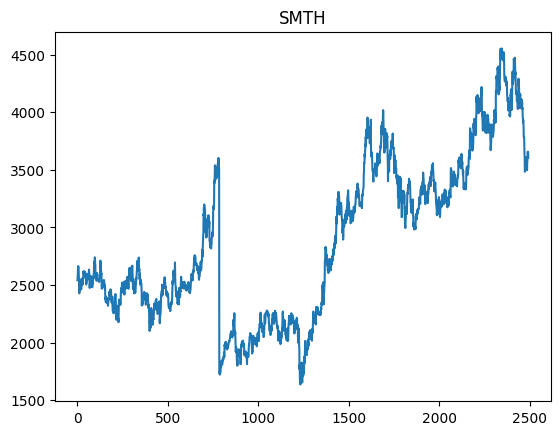

Index(['Symbol', 'Series', 'Date', 'Prev Close', 'Open Price', 'High Price',
       'Low Price', 'Last Price', 'Close Price', 'Average Price',
       'Total Traded Quantity', 'Turnover ₹', 'No. of Trades'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2492 entries, 0 to 2491
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Symbol                 2492 non-null   object 
 1   Series                 2492 non-null   object 
 2   Date                   2492 non-null   object 
 3   Prev Close             2492 non-null   object 
 4   Open Price             2492 non-null   object 
 5   High Price             2492 non-null   object 
 6   Low Price              2492 non-null   object 
 7   Last Price             2492 non-null   object 
 8   Close Price            2492 non-null   float64
 9   Average Price          2492 non-null   object 
 10  Total Traded Quantity  2492 non-nul

In [ ]:
data = pd.read_csv('compiled security TCS.csv')
data.columns = data.columns.str.strip() # Strip whitespace from column names
data['Close Price'] = data['Close Price'].astype(str).str.replace(',', '', regex=False)
data['Close Price'] = pd.to_numeric(data['Close Price'], errors='coerce')
ts = data['Close Price']

ts.plot(title='SMTH')
plt.show()
print(data.columns)
data.info()

In [ ]:
ts = ts.dropna()
result = adfuller(ts)
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])

if result[1] > 0.05:
    print("Series is non stationary; differencing is needed.")
else:
    print("Series is stationary; no differencing needed.")

ADF Statistic: -1.846404
p-value: 0.357679
Series is non stationary; differencing is needed.


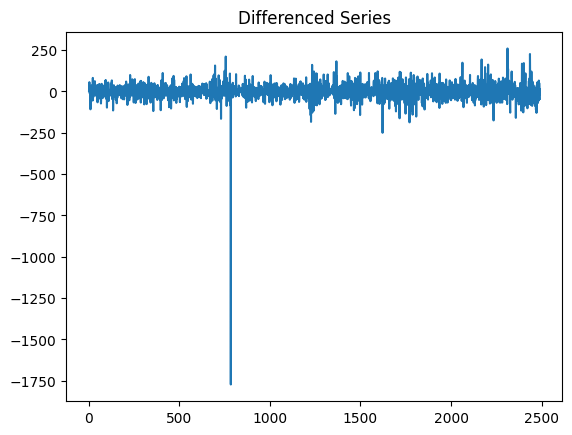

ADF Statistic (differenced): -49.386953
p-value (differenced): 0.000000


In [ ]:
ts_diff = ts.diff().dropna()

ts_diff.plot(title='Differenced Series')
plt.show()

result_diff = adfuller(ts_diff)
print('ADF Statistic (differenced): %f' % result_diff[0])
print('p-value (differenced): %f' % result_diff[1])

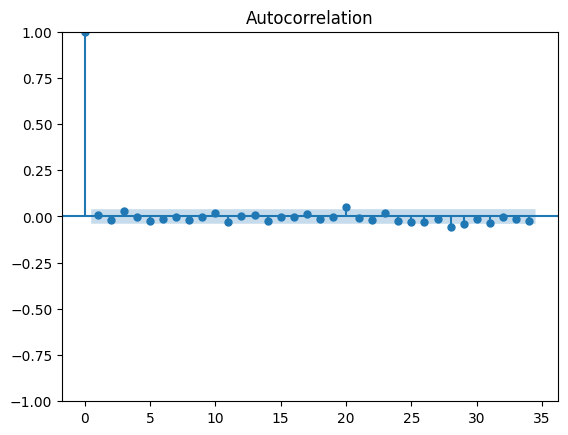

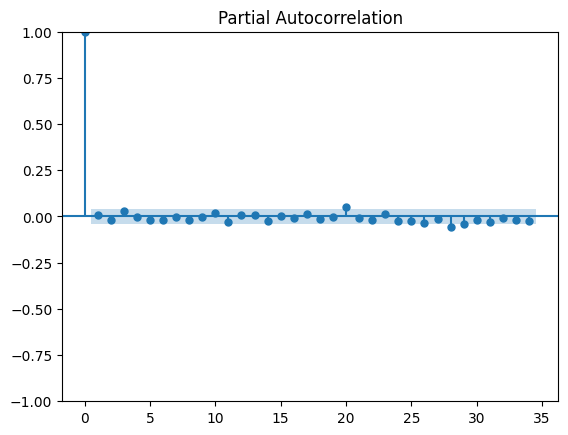

In [ ]:
plot_acf(ts_diff)
plt.show()

plot_pacf(ts_diff)
plt.show()

In [ ]:
p, d, q = 2, 1, 3
P, D, Q, s = 2, 1, 3, 10

model = SARIMAX(ts, order=(p, d, q), seasonal_order=(P, D, Q, s))
results = model.fit(disp=False)

In [ ]:
forecast_steps = 10 # Number of steps to forecast
forecast_values = results.predict(start=len(ts), end=len(ts) + forecast_steps - 1)

# For plotting purposes, align the index of forecast_values with the expected time period
# Assuming ts has a DatetimeIndex for proper alignment, otherwise a simple range will be used
if isinstance(ts.index, pd.DatetimeIndex):
    last_date = ts.index[-1]
    forecast_index = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=forecast_steps, freq='B') # Business day frequency
    forecast_values.index = forecast_index
else:
    # If original index is not datetime, just use an integer range for simplicity
    forecast_values.index = range(len(ts), len(ts) + forecast_steps)

print("Forecast values generated.")

Forecast values generated.


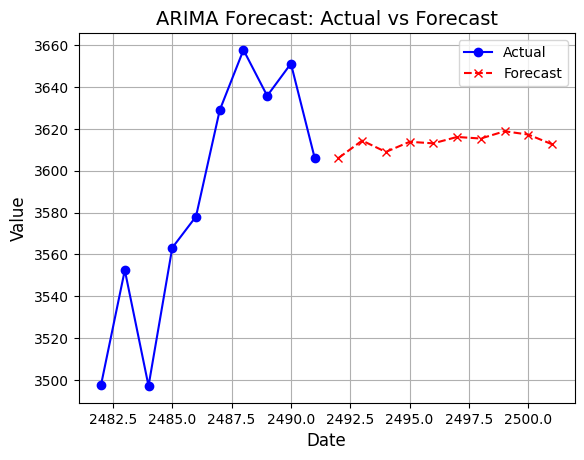

In [ ]:
plt.plot(ts[-10:].index, ts[-10:], label='Actual', color='blue', linestyle='-', marker='o')
plt.plot(forecast_values.index, forecast_values, label='Forecast', color='red', linestyle='--', marker='x')

plt.title('ARIMA Forecast: Actual vs Forecast', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                        Close Price   No. Observations:                 2492
Model:             SARIMAX(2, 1, 3)x(2, 1, 3, 10)   Log Likelihood              -13471.282
Date:                            Sat, 22 Nov 2025   AIC                          26964.564
Time:                                    20:02:05   BIC                          27028.545
Sample:                                         0   HQIC                         26987.801
                                           - 2492                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3240      0.568     -0.571      0.568      -1.437       0.788
ar.L2         -0.4659      0.631   